# Model-Based Machine Learning en Telecomunicaciones: Deep Unfolding
**Objetivo:** Comparar tres enfoques para resolver un problema clásico de detección de señales MIMO ($\mathbf{y} = \mathbf{H}\mathbf{x} + \mathbf{n}$):
1. **Model-Based Clásico (PGD):** Algoritmo iterativo de Descenso de Gradiente Proyectado con paso fijo.

$$x=arg\min_{x} ​∥y−Hx∥^2$$

sujeto a:

$$x_i ∈ \{−1,+1\} $$

2. **Data-Driven (Caja Negra):** Red Neuronal Densa (MLP) estándar sin conocimiento previo del canal $\mathbf{H}$.

3. **Model-Based ML (Deep Unfolding):** Red neuronal cuya arquitectura imita $L$ iteraciones del algoritmo PGD, aprendiendo los parámetros óptimos a partir de los datos.


### Configuración y Simulación del Canal MIMO (Multiple Input Multiple Output)

Se generan los símbolos transmitidos (constelación BPSK {-1, +1}), la matriz de canal H y el ruido AWGN. El sistema consta de MIMO 4x4.

In [10]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Configuración de reproducibilidad y dispositivo
torch.manual_seed(17)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Parámetros del sistema MIMO
N_TX = 4   #Antenas Tx (transmisión)
N_RX = 4   #Antenas Rx (recepción)
BATCH_SIZE = 2000

# Se generan los canales MIMO
def generar_datos_mimo(num_muestras, snr_db):
    # Símbolos transmitidos BPSK {-1, +1}
    x = torch.randint(0, 2, (num_muestras, N_TX, 1), device=device).float() * 2 - 1
    
    # Canal Rayleigh plano (matriz H conocida en el receptor)
    H = torch.randn(num_muestras, N_RX, N_TX, device=device) / np.sqrt(N_RX)
    
    # Señal recibida sin ruido y cálculo de varianza del ruido AWGN
    Hx = torch.bmm(H, x)
    snr_lineal = 10 ** (snr_db / 10.0)
    potencia_ruido = 1.0 / snr_lineal
    ruido = torch.randn_like(Hx) * np.sqrt(potencia_ruido)
    
    y = Hx + ruido
    return x, H, y

# Prueba rápida de generación
x_test, H_test, y_test = generar_datos_mimo(5, snr_db=10)
print(f"Forma de señal recibida y: {y_test.shape}")


Forma de señal recibida y: torch.Size([5, 4, 1])



### Definición de los 3 Modelos

Aquí se observa el contraste entre el método analítico, la caja negra y el modelo híbrido (Deep Unfolding).

In [ ]:
# Modelo 1: Algoritmo Clásico (Projected Gradient Descent - PGD)
def detector_pgd_clasico(y, H, iteraciones=5, paso_fijo=0.5):
    x_est = torch.zeros((y.shape[0], N_TX, 1), device=device)
    HT = H.transpose(1, 2)
    
    for _ in range(iteraciones):
        # Gradiente de ||y - Hx||^2 es -H^T(y - Hx)
        residuo = y - torch.bmm(H, x_est)
        gradiente = -torch.bmm(HT, residuo)
        # Actualización y proyección suave (tanh) hacia {-1, +1}
        x_est = torch.tanh(x_est - paso_fijo * gradiente)
    return x_est

# Modelo 2: Data-Driven Puro (Red Neuronal Caja Negra)
class DetectorDataDriven(nn.Module):
    def __init__(self):
        super().__init__()
        # Recibe: y (4) + H aplanada (4x4) = 20 entradas
        self.red = nn.Sequential(
            nn.Linear(N_RX + N_RX * N_TX, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, N_TX),
            nn.Tanh()   #Se utiliza tanh para proyectar la salida a {-1, +1}
        )
        
    def forward(self, y, H):
        entrada = torch.cat([y.squeeze(-1), H.view(y.shape[0], -1)], dim=1)
        return self.red(entrada).unsqueeze(-1)

# Modelo 3: Model-Based ML (Deep Unfolding PGD)
class DetectorDeepUnfolding(nn.Module):
    def __init__(self, capas=5):
        super().__init__()
        self.capas = capas
        # En lugar de un paso fijo, cada capa aprende su propio tamaño de paso (gamma) y su propia escala de proyección (theta)
        self.gammas = nn.Parameter(torch.ones(capas) * 0.5)
        self.thetas = nn.Parameter(torch.ones(capas) * 1.0)
        
    def forward(self, y, H):
        x_est = torch.zeros((y.shape[0], N_TX, 1), device=device)
        HT = H.transpose(1, 2)
        
        for k in range(self.capas):
            residuo = y - torch.bmm(H, x_est)
            gradiente = -torch.bmm(HT, residuo)
            x_est = torch.tanh(self.thetas[k] * (x_est - self.gammas[k] * gradiente))
        return x_est

# Comparación de cantidad de parámetros entrenables
modelo_data_driven = DetectorDataDriven().to(device)
modelo_unfolded = DetectorDeepUnfolding(capas=5).to(device)

print(f"Parámetros Caja Negra (MLP): {sum(p.numel() for p in modelo_data_driven.parameters())}")
print(f"Parámetros Model-Based (Deep Unfolding): {sum(p.numel() for p in modelo_unfolded.parameters())}")

Parámetros Caja Negra (MLP): 5764
Parámetros Model-Based (Deep Unfolding): 10



### Entrenamiento con Pocos Datos

Una ventaja clave de Model-Based ML es la eficiencia de datos. Se entrenan ambos modelos con muy pocas épocas para demostrar cómo Model-Based ML converge mas rápido

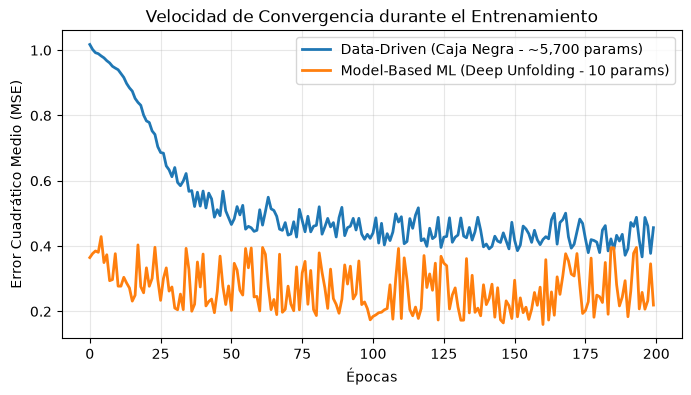

In [16]:
def entrenar_modelo(modelo, epocas=150, lr=0.01):
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)  # Optimizador: Adam con taza de aprendizaje de 0.01
    criterio = nn.MSELoss()                                     # Función de pérdida: Error cuadrático medio (MSE)
    historial_loss = []
    
    for epoca in range(epocas):
        snr_random = np.random.uniform(5, 15)   # Se entrena con un rango variado de SNR (5 a 15 dB)
        x_train, H_train, y_train = generar_datos_mimo(BATCH_SIZE, snr_random)  #Se generan los canales MIMO
        
        optimizador.zero_grad()             # 1. Reiniciar gradientes
        x_pred = modelo(y_train, H_train)   # 2. Propagación hacia adelante (Forward)
        loss = criterio(x_pred, x_train)    # 3. Calcular error
        loss.backward()                     # 4. Retropropagación (Backpropagation)
        optimizador.step()                  # 5. Actualizar pesos
        
        historial_loss.append(loss.item())
    return historial_loss

loss_data_driven = entrenar_modelo(modelo_data_driven, epocas=200, lr=0.005)
loss_unfolded = entrenar_modelo(modelo_unfolded, epocas=200, lr=0.02)

# Gráfica de convergencia
plt.figure(figsize=(8, 4))
plt.plot(loss_data_driven, label='Data-Driven (Caja Negra - ~5,700 params)', linewidth=2)
plt.plot(loss_unfolded, label='Model-Based ML (Deep Unfolding - 10 params)', linewidth=2)
plt.title('Velocidad de Convergencia durante el Entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Error Cuadrático Medio (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Evaluación de Tasa de Error de Bit (BER vs SNR)

Esta celda genera la gráfica estándar de telecomunicaciones (BER vs SNR) para demostrar el rendimiento real de los tres métodos.

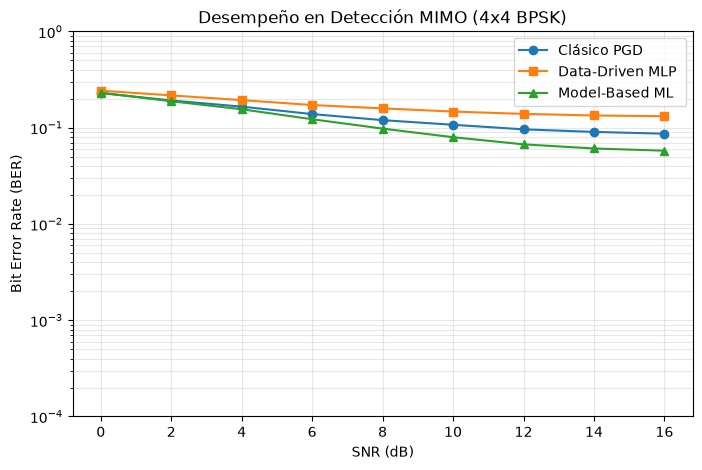

In [17]:
snrs_db = np.arange(0, 18, 2)
ber_clasico, ber_data_driven, ber_unfolded = [], [], []

modelo_data_driven.eval()
modelo_unfolded.eval()

with torch.no_grad():
    for snr in snrs_db:
        x_val, H_val, y_val = generar_datos_mimo(10000, snr)
        
        # Predicciones
        pred_clasico = torch.sign(detector_pgd_clasico(y_val, H_val, iteraciones=5))
        pred_data_driven = torch.sign(modelo_data_driven(y_val, H_val))
        pred_unfolded = torch.sign(modelo_unfolded(y_val, H_val))
        
        # Cálculo de BER
        ber_clasico.append((pred_clasico != x_val).float().mean().item())
        ber_data_driven.append((pred_data_driven != x_val).float().mean().item())
        ber_unfolded.append((pred_unfolded != x_val).float().mean().item())

plt.figure(figsize=(8, 5))
plt.semilogy(snrs_db, ber_clasico, 'o-', label='Clásico PGD ')
plt.semilogy(snrs_db, ber_data_driven, 's-', label='Data-Driven MLP ')
plt.semilogy(snrs_db, ber_unfolded, '^-', label='Model-Based ML ')
plt.title('Desempeño en Detección MIMO (4x4 BPSK)')
plt.xlabel('SNR (dB)')
plt.ylabel('Bit Error Rate (BER)')
plt.ylim([1e-4, 1])
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()